
# <span style="color:green"> Laboratorio di Simulazione Numerica </span>
## Tommaso Cardano Chiezzi
# Esercizio 01.1 — Test del generatore pseudo-casuale

L'obiettivo dell'esercizio è verificare il comportamento del generatore `Rannyu()` attraverso tre controlli:

1. stima del valor medio di una variabile uniforme $ r\in[0,1) $;
2. stima della sua varianza;
3. test del $\chi^2$ per verificare la compatibilità con una distribuzione uniforme.

I risultati numerici vengono prodotti dal programma C++ e salvati nei file:

- `AV_prog_Err_prog.txt`
- `AV_prog_VAR_Err_prog_VAR.txt`
- `Chi2.txt`





# 01.1.1 — Stima di $\langle r\rangle$

Si consideri una variabile casuale $r$ uniformemente distribuita nell'intervallo $[0,1)$.  
Il suo valore medio teorico è

$$
\langle r\rangle
=
\int_0^1 r\,dr
=
\frac{1}{2}.
$$

L'obiettivo di questa prima parte è **stimare numericamente questo valore mediante un metodo Monte Carlo**, utilizzando i numeri pseudo-casuali generati dal generatore `Rannyu()`.

Se si generano $M$ valori indipendenti tra $[0, 1)$

$$
r_1,r_2,\ldots,r_M,
$$

una stima Monte Carlo del valor medio è data dalla loro media aritmetica:

$$
\langle r\rangle_M
\simeq
\frac{1}{M}\sum_{j=1}^{M}r_j.
$$

Aumentando il numero di estrazioni $M$, ci si aspetta che questa stima converga al valore teorico $1/2$.

Per ottenere anche una stima dell'**incertezza statistica**, viene utilizzato il metodo del **data blocking**.

## Data blocking

Le $M$ estrazioni vengono suddivise in $N$ blocchi, ciascuno formato da

$$
L=\frac{M}{N}
$$

numeri casuali, in modo che

$$
M=N\,L.
$$

Nel nostro caso si utilizzano

$$
M=100000,
\qquad
N=100,
\qquad
L=1000.
$$

Per ciascun blocco $i$ viene calcolata la media dei $L$ numeri casuali contenuti al suo interno:

$$
A_i
=
\frac{1}{L}
\sum_{j=1}^{L} r_j.
$$

Ogni $A_i$ rappresenta quindi una **stima indipendente di $\langle r\rangle$ ottenuta dal singolo blocco**.

A partire dalle medie di blocco si costruisce poi la media progressiva. Dopo aver utilizzato i primi $n$ blocchi:

$$
\langle A\rangle_n
=
\frac{1}{n}
\sum_{i=1}^{n} A_i.
$$

Viene calcolata inoltre la media progressiva dei quadrati delle medie di blocco:

$$
\langle A^2\rangle_n
=
\frac{1}{n}
\sum_{i=1}^{n} A_i^2.
$$

Queste due quantità permettono di stimare l'incertezza statistica associata alla media progressiva:

$$
\sigma_n
=
\sqrt{
\frac{
\langle A^2\rangle_n
-
\langle A\rangle_n^2
}{
n-1
}
}.
$$

Il denominatore è $n-1$ perché l'incertezza viene stimata a partire da $n$ valori di blocco. Per il primo blocco, $n=1$, non è ancora possibile stimare la dispersione e quindi nel programma l'errore viene posto uguale a zero.

### Perché usare il data blocking?

Il data blocking non serve solo a calcolare una media, ma soprattutto a ottenere una **stima affidabile dell'incertezza statistica**.

Se le singole misure fossero tutte indipendenti, si potrebbe applicare direttamente le formule standard della statistica. Nelle simulazioni Monte Carlo, però, questo non è sempre vero.

In presenza di correlazioni, il numero di misure realmente indipendenti è minore del numero totale di misure effettuate. Se si ignorasse questo effetto, si tenderebbe a **sottostimare l'errore statistico**.

L'idea del data blocking è quindi quella di sostituire le singole misure con le medie dei blocchi:

$$
A_1,A_2,\ldots,A_N.
$$

Se ciascun blocco contiene un numero sufficientemente grande di misure, le correlazioni presenti tra misure vicine vengono in gran parte "assorbite" all'interno del blocco e le medie di blocchi differenti possono essere considerate approssimativamente indipendenti.

In questo modo si può applicare alle medie di blocco la formula standard per l'incertezza statistica.



### Scelta di $M$, $N$ e $L$

Le tre quantità sono legate da

$$
M=N\,L,
$$

dove:

- $M$ è il numero totale di misure;
- $N$ è il numero di blocchi;
- $L$ è il numero di misure contenute in ciascun blocco.

La scelta deve bilanciare due esigenze opposte.

Il blocco deve essere abbastanza lungo, cioè $L$ abbastanza grande, da rendere le medie di blocchi diversi circa indipendenti. Se esiste un tempo di correlazione caratteristico $\tau_c$, idealmente si vuole scegliere

$$
L \gg \tau_c,
$$

dove $\tau_c$ è espresso in numero di passi o misure della simulazione.

D'altra parte, non conviene scegliere blocchi troppo grandi, perché a $M$ fissato vale

$$
N=\frac{M}{L},
$$

e quindi aumentando troppo $L$ diminuisce il numero di blocchi disponibili. Se $N$ diventa troppo piccolo, la stima dell'errore diventa a sua volta poco stabile.

In pratica si cerca quindi un compromesso:

$$
\text{blocchi abbastanza lunghi da eliminare le correlazioni}
$$

ma contemporaneamente

$$
\text{un numero di blocchi abbastanza grande da stimare bene l'errore}.
$$

Un criterio pratico consiste nel ripetere l'analisi aumentando progressivamente $L$: quando la stima dell'errore raggiunge un plateau e non cambia più in modo significativo, la lunghezza del blocco può essere considerata sufficientemente grande.

Nelle nostre analisi il generatore `Rannyu()` è progettato per produrre numeri non correlati, quindi il problema delle correlazioni è molto meno critico rispetto ad altre simulazioni. La scelta

$$
M=100000,
\qquad
N=100,
\qquad
L=1000
$$

fornisce comunque un numero elevato di estrazioni per blocco e un numero sufficiente di blocchi per osservare bene la convergenza e stimare l'incertezza statistica.




## Quantità rappresentata

Per verificare più facilmente la convergenza al risultato teorico non si rappresenta direttamente $\langle r\rangle$, ma la differenza

$$
\langle r\rangle-\frac{1}{2}.
$$

Il valore teorico corrisponde quindi a

$$
\langle r\rangle-\frac{1}{2}=0.
$$

Nel grafico mostreremo questa quantità in funzione del **numero cumulativo di estrazioni**, con le relative barre d'errore ottenute tramite data blocking.

Se il generatore `Rannyu()` si comporta correttamente, ci si aspetta che la stima progressiva oscilli attorno a zero e diventi progressivamente più piccola all'aumentare del numero di blocchi utilizzati.

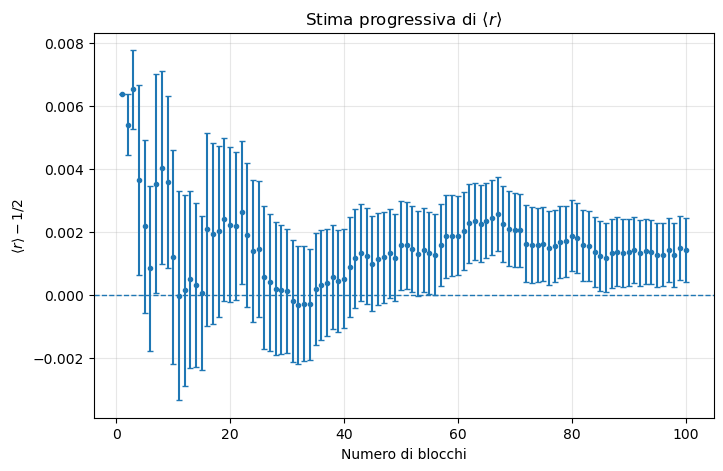

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# File 01.1.1: media di blocco, media progressiva, errore progressivo
media_blocco, media_progressiva, errore_media = np.loadtxt(
    "Esercizio_01.1\AV_prog_Err_prog.txt",
    unpack=True
)

# File 01.1.2: stima di blocco, stima progressiva, errore progressivo
varianza_blocco, varianza_progressiva, errore_varianza = np.loadtxt(
    "Esercizio_01.1\AV_prog_VAR_Err_prog_VAR.txt",
    unpack=True
)

# File 01.1.3: indice del test, valore del chi-quadro
indice_test, chi_quadro = np.loadtxt(
    "Esercizio_01.1\Chi2.txt",
    unpack=True
)

# Parametri usati nel programma C++
M = 100000
N = len(media_blocco)
L = M // N

# Numero cumulativo di estrazioni dopo ogni blocco
numero_blocco = np.arange(1, N + 1) 




valore_teorico_media = 0.5
scarto_media = media_progressiva - valore_teorico_media

plt.figure(figsize=(8, 5))

plt.errorbar(
    numero_blocco,
    scarto_media,
    yerr=errore_media,
    fmt="o",
    markersize=3,
    capsize=2
)

plt.axhline(0.0, linestyle="--", linewidth=1)

plt.xlabel("Numero di blocchi")
plt.ylabel(r"$\langle r \rangle - 1/2$")
plt.title(r"Stima progressiva di $\langle r \rangle$")
plt.grid(alpha=0.3)

plt.show()



Le oscillazioni attorno a zero sono dovute alle fluttuazioni statistiche.  
Si osserva che aumentando il numero di blocchi, la media progressiva tende a stabilizzarsi e l'incertezza diminuisce.



# 01.1.2 — Stima della varianza

La seconda quantità richiesta è

$$
\sigma^2
=
\left\langle
\left(r-\frac{1}{2}\right)^2
\right\rangle.
$$

Per una distribuzione uniforme in \([0,1)\),

$$
\sigma^2
=
\int_0^1
\left(r-\frac{1}{2}\right)^2dr
=
\frac{1}{12}.
$$

Il programma campiona direttamente l'osservabile

$$
\left(r-\frac{1}{2}\right)^2
$$

e applica lo stesso metodo di data blocking.

Nel grafico si rappresenta quindi

$$
\sigma^2-\frac{1}{12}.
$$


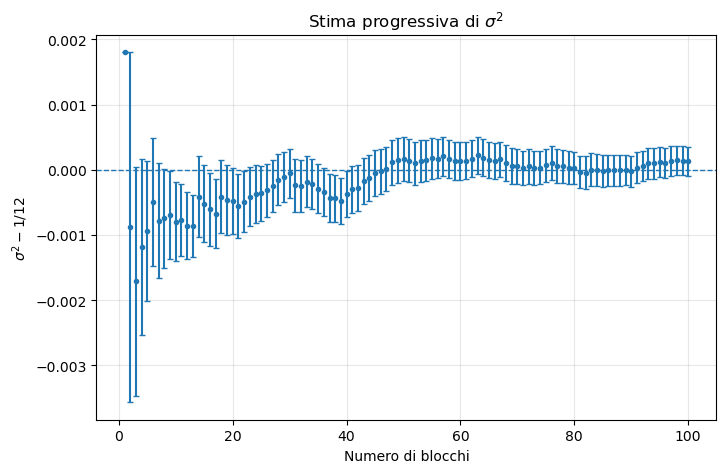

In [11]:
valore_teorico_varianza = 1.0 / 12.0
scarto_varianza = varianza_progressiva - valore_teorico_varianza

plt.figure(figsize=(8, 5))

plt.errorbar(
    numero_blocco,
    scarto_varianza,
    yerr=errore_varianza,
    fmt="o",
    markersize=3,
    capsize=2
)

plt.axhline(0.0, linestyle="--", linewidth=1)

plt.xlabel("Numero di blocchi")
plt.ylabel(r"$\sigma^2 - 1/12$")
plt.title(r"Stima progressiva di $\sigma^2$")
plt.grid(alpha=0.3)

plt.show()



Anche in questo caso il valore teorico corrisponde alla linea a zero.  
Anche in questo caso si osserva che l'incertezza statistica diminuisce all'aumentare del numero di blocchi

# 01.1.3 — Test del $\chi^2$

In questa parte si vuole verificare se i numeri pseudo-casuali prodotti dal generatore `Rannyu()` sono **statisticamente compatibili con una distribuzione uniforme** nell'intervallo $[0,1)$.

Un test statistico non può dimostrare che il generatore di numeri casuali produca numeri effettivamente casuali distribuiti uniformemente tra $[0, 1$. Si può però formulare come ipotesi nulla

$$
H_0:\quad r \sim U(0,1)
$$

e verificare se gli scostamenti osservati rispetto a questa ipotesi sono compatibili con le normali fluttuazioni statistiche oppure sono troppo grandi.

Per farlo viene utilizzato il **test del chi-quadro di Pearson**.

L'intervallo $[0,1)$ viene diviso in

$$
N_{\mathrm{bin}}=100
$$

intervalli della stessa ampiezza.

In ciascun test vengono generati

$$
n=10000
$$

numeri pseudo-casuali.

Se l'ipotesi di distribuzione uniforme è corretta, ogni numero ha la stessa probabilità di cadere in ciascun bin:

$$
p_i=\frac{1}{N_{\mathrm{bin}}}.
$$

Il numero atteso di eventi nel bin $i$ è quindi

$$
E_i
=
n p_i
=
\frac{n}{N_{\mathrm{bin}}}
=
\frac{10000}{100}
=
100.
$$

Viene indicato invece con $O_i$ il numero di eventi effettivamente osservati nel bin $i$.

La statistica di Pearson è definita come

$$
\chi^2
=
\sum_{i=1}^{N_{\mathrm{bin}}}
\frac{(O_i-E_i)^2}{E_i}.
$$

Ogni termine misura quindi lo scostamento tra il numero osservato e quello atteso, pesato rispetto all'ampiezza delle fluttuazioni statistiche attese.

Se i valori osservati sono vicini a quelli attesi, il valore di $\chi^2$ rimane relativamente piccolo; deviazioni sistematicamente grandi producono invece valori elevati di $\chi^2$ e possono indicare una scarsa compatibilità con l'ipotesi di uniformità.

I conteggi dei diversi bin non sono completamente indipendenti, perché il numero totale di eventi deve sempre soddisfare

$$
\sum_{i=1}^{N_{\mathrm{bin}}} O_i = 10000.
$$

Una volta noti i conteggi di $99$ bin, quello dell'ultimo bin è quindi automaticamente determinato. Il numero di gradi di libertà è

$$
\nu
=
N_{\mathrm{bin}}-1
=
99.
$$

Se l'ipotesi nulla è valida, la statistica calcolata segue approssimativamente una distribuzione $\chi^2$ con $\nu=99$ gradi di libertà.

Per tale distribuzione il valore medio teorico è

$$
\langle\chi^2\rangle
=
\nu
=
99,
$$

mentre la deviazione standard è

$$
\sigma_{\chi^2}
=
\sqrt{2\nu}
=
\sqrt{198}
\simeq 14.1.
$$

Ripetendo il test $100$ volte non ci si aspetta quindi di ottenere sempre $\chi^2=99$, ma una serie di valori distribuiti attorno a $99$, con fluttuazioni dell'ordine di $14$.

Se i valori ottenuti mostrano questo comportamento, il risultato è compatibile con l'ipotesi che `Rannyu()` generi numeri uniformemente distribuiti in $[0,1)$.

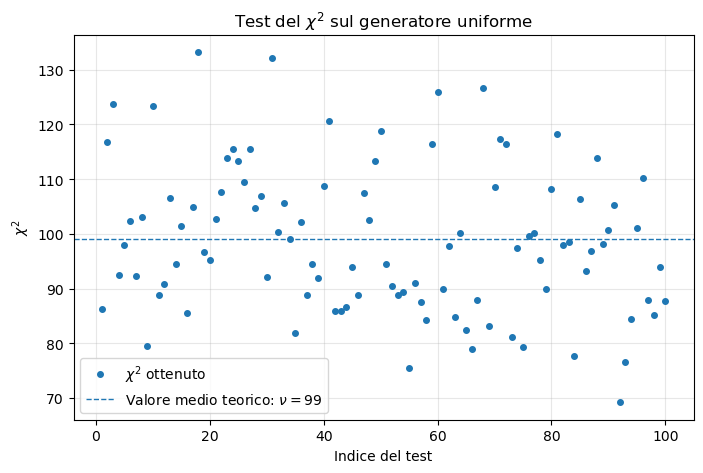

In [33]:
numero_bin = 100
gradi_liberta = numero_bin - 1

media_chi2_teorica = gradi_liberta
dev_std_chi2_teorica = np.sqrt(2 * gradi_liberta)

plt.figure(figsize=(8, 5))

plt.plot(
    indice_test,
    chi_quadro,
    "o",
    markersize=4,
    label=r"$\chi^2$ ottenuto"
)

plt.axhline(
    media_chi2_teorica,
    linestyle="--",
    linewidth=1,
    label=r"Valore medio teorico: $\nu=99$"
)

plt.xlabel("Indice del test")
plt.ylabel(r"$\chi^2$")
plt.title(r"Test del $\chi^2$ sul generatore uniforme")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


Come si nota dal grafico, i valori sono distribuiti intorno al valor medio  $\nu=99$

## Confronto con la distribuzione $\chi^2$ teorica

Se l'ipotesi di uniformità del generatore è corretta, i valori ottenuti nei diversi test devono essere compatibili con una distribuzione chi-quadro con

$$
\nu = N_{\mathrm{bin}} - 1 = 99
$$

gradi di libertà.

Per confrontare i risultati numerici con la distribuzione teorica, viene rappresentato l'istogramma normalizzato dei valori di $\chi^2$ ottenuti, a cui viene sovrapposta la densità di probabilità teorica di una distribuzione $\chi^2_{99}$.

Con soli 100 test non ci si aspetta che l'istogramma riproduca perfettamente la curva teorica, ma forma, posizione e dispersione dovrebbero risultare compatibili.


### Compatibilità della media simulata

La media teorica di una distribuzione $\chi^2$ con $\nu=99$ gradi di libertà è

$$
\langle\chi^2\rangle_{\mathrm{teo}}=99.
$$

Dai $N_{\mathrm{test}}=100$ test si ottiene invece una media simulata

$$
\langle\chi^2\rangle_{\mathrm{sim}}
=
\frac{1}{N_{\mathrm{test}}}
\sum_{i=1}^{N_{\mathrm{test}}}\chi_i^2.
$$

Poiché la media viene calcolata su un numero finito di test, essa è soggetta a un'incertezza statistica. Una stima di tale errore è

$$
\sigma_{\langle\chi^2\rangle}
=
\frac{s_{\chi^2}}{\sqrt{N_{\mathrm{test}}}},
$$

dove $s_{\chi^2}$ è la deviazione standard dei valori ottenuti nella simulazione.

La media simulata può quindi essere confrontata con il valore teorico $99$ tenendo conto di questa incertezza. Se la differenza tra i due valori è dello stesso ordine dell'errore statistico, i risultati sono compatibili con la distribuzione $\chi^2$ attesa.

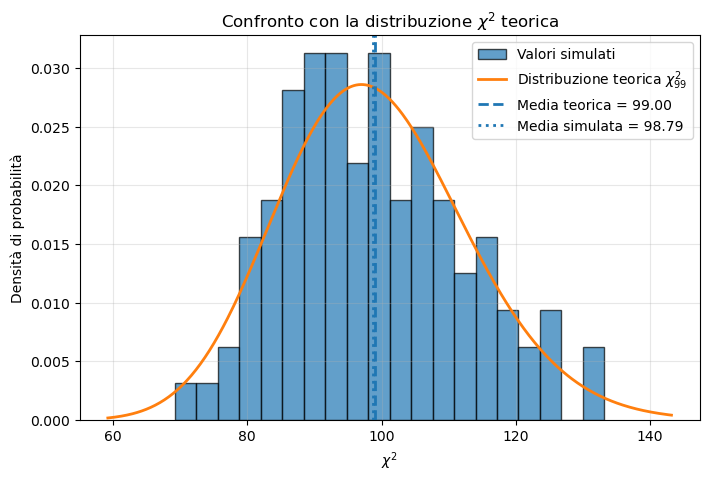

Media teorica:                    99.00
Media simulata:                   98.79
Errore sulla media simulata:      1.35

Deviazione standard teorica:      14.07
Deviazione standard simulata:     13.51

Errore teorico atteso sulla media: 1.41


In [41]:
from scipy.stats import chi2

# Numero di gradi di libertà
gradi_liberta = numero_bin - 1

# Numero di test effettuati
numero_test = len(chi_quadro)

# Valori teorici della distribuzione chi-quadro
media_teorica = gradi_liberta
dev_std_teorica = np.sqrt(2 * gradi_liberta)

# Valori ottenuti dalla simulazione
media_simulata = np.mean(chi_quadro)
dev_std_simulata = np.std(chi_quadro, ddof=1)

# Errore sulla media simulata
errore_media_simulata = dev_std_simulata / np.sqrt(numero_test)

# Errore teorico atteso sulla media
errore_media_teorico = dev_std_teorica / np.sqrt(numero_test)

# Intervallo su cui disegnare la distribuzione teorica
x = np.linspace(
    max(0, chi_quadro.min() - 10),
    chi_quadro.max() + 10,
    500
)

# Densità di probabilità teorica
pdf_teorica = chi2.pdf(x, df=gradi_liberta)

plt.figure(figsize=(8, 5))

# Istogramma dei valori simulati
plt.hist(
    chi_quadro,
    bins=20,
    density=True,
    alpha=0.7,
    edgecolor="black",
    label="Valori simulati"
)

# Distribuzione teorica
plt.plot(
    x,
    pdf_teorica,
    linewidth=2,
    label=rf"Distribuzione teorica $\chi^2_{{{gradi_liberta}}}$"
)

# Media teorica
plt.axvline(
    media_teorica,
    linestyle="--",
    linewidth=2,
    label=rf"Media teorica = {media_teorica:.2f}"
)

# Media simulata
plt.axvline(
    media_simulata,
    linestyle=":",
    linewidth=2,
    label=rf"Media simulata = {media_simulata:.2f}"
)

plt.xlabel(r"$\chi^2$")
plt.ylabel("Densità di probabilità")
plt.title(r"Confronto con la distribuzione $\chi^2$ teorica")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


# Confronto numerico
print(f"Media teorica:                    {media_teorica:.2f}")
print(f"Media simulata:                   {media_simulata:.2f}")
print(f"Errore sulla media simulata:      {errore_media_simulata:.2f}")
print()

print(f"Deviazione standard teorica:      {dev_std_teorica:.2f}")
print(f"Deviazione standard simulata:     {dev_std_simulata:.2f}")
print()

print(f"Errore teorico atteso sulla media: {errore_media_teorico:.2f}")

Come si nota dal grafico, la distribuzione di numeri pseudo-casuali generati tra $[0, 1)$ è compatibile con una distribuzione uniforme entro l'incertezza, di conseguenza il test risulta superato. Si può notare come la presenza di lunghe code sulla parte destra dell'istogramma sia compatibile con l'andamento teorico della funzione  $\chi^2$

# Esercizio 01.2 — Verifica del teorema del limite centrale

# 01.2 — Teorema del Limite Centrale

In questo esercizio vogliamo verificare numericamente il **Teorema del Limite Centrale** studiando la distribuzione della variabile

$$
S_N=\frac{1}{N}\sum_{i=1}^{N}x_i,
$$

dove gli $x_i$ sono variabili casuali indipendenti estratte dalla stessa distribuzione.

Si considerino quattro diversi valori di $N$:

$$
N=1,\;2,\;10,\;100
$$

e, per ciascun valore, vengono generati $10^4$ realizzazioni di $S_N$.

Si ripete l'esperimento per tre diverse distribuzioni di partenza:

- distribuzione uniforme in $[0,1)$;
- distribuzione esponenziale con $\lambda=1$;
- distribuzione di Cauchy-Lorentz con $\mu=0$ e $\Gamma=1$.

Il **Teorema del Limite Centrale** afferma che, indipendentemente dalla distribuzione di partenza delle variabili casuali $x_i$, se i primi due momenti esistono e sono finiti, la distribuzione della loro media $S_N$ tende a una distribuzione Gaussiana all'aumentare di $N$.

Se la distribuzione di partenza ha media $\mu$ e varianza $\sigma^2$, allora per $S_N$:

$$
\langle S_N\rangle=\mu
$$

e

$$
\mathrm{Var}(S_N)=\frac{\sigma^2}{N}.
$$

La larghezza della distribuzione diminuisce quindi come

$$
\sigma_{S_N}=\frac{\sigma}{\sqrt{N}}.
$$

La distribuzione di Cauchy-Lorentz rappresenta invece un caso particolare, perché non possiede media e varianza finite e quindi non soddisfa le ipotesi del Teorema del Limite Centrale nella sua forma standard.

In [45]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import norm, cauchy

# Ogni file contiene quattro colonne:
# N = 1, 2, 10, 100

standard = np.loadtxt("Esercizio_01.2\Standard_dice.txt")
exponential = np.loadtxt("Esercizio_01.2\Exponential_dice.txt")
lorentzian = np.loadtxt("Esercizio_01.2\Lorentzian_dice.txt")

valori_n = [1, 2, 10, 100]

print("Numero di realizzazioni:", standard.shape[0])
print("Valori di N:", valori_n)

Numero di realizzazioni: 10000
Valori di N: [1, 2, 10, 100]


## Distribuzione uniforme

Nel primo caso ogni $x_i$ è estratto da una distribuzione uniforme in $[0,1)$:

$$
x_i\sim U(0,1).
$$

Per questa distribuzione:

$$
\mu=\frac{1}{2},
$$

$$
\sigma^2=\frac{1}{12}.
$$

La variabile

$$
S_N=\frac{1}{N}\sum_{i=1}^{N}x_i
$$

mantiene quindi valore medio

$$
\langle S_N\rangle=\frac{1}{2},
$$

mentre la sua varianza diminuisce come

$$
\mathrm{Var}(S_N)=\frac{1}{12N}.
$$

Ci si aspetta quindi che, aumentando $N$, la distribuzione diventi progressivamente più stretta attorno a $1/2$ e assuma una forma sempre più simile a una Gaussiana.

Per $N=100$ viene sovrapposto all'istogramma anche un fit Gaussiano.

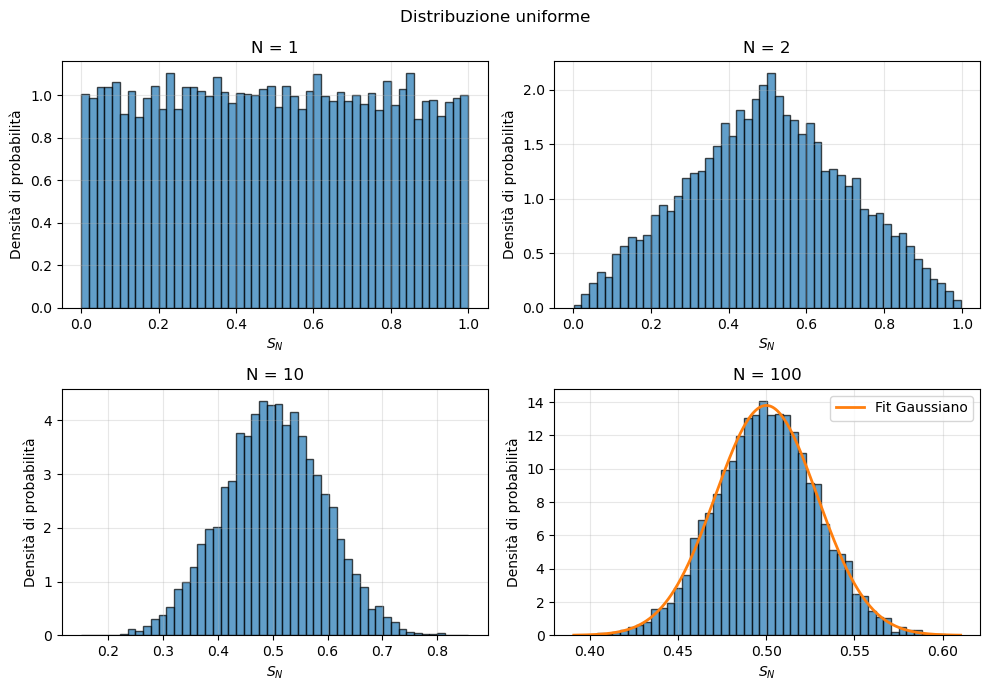

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes = axes.flatten()

for i, n in enumerate(valori_n):

    dati = standard[:, i]

    axes[i].hist(
        dati,
        bins=50,
        density=True,
        alpha=0.7,
        edgecolor="black"
    )

    axes[i].set_title(f"N = {n}")
    axes[i].set_xlabel(r"$S_N$")
    axes[i].set_ylabel("Densità di probabilità")
    axes[i].grid(alpha=0.3)


# Fit Gaussiano per N = 100
dati_n100 = standard[:, 3]

mu_fit_standard, sigma_fit_standard = norm.fit(dati_n100)

x = np.linspace(dati_n100.min(), dati_n100.max(), 500)

axes[3].plot(
    x,
    norm.pdf(x, mu_fit_standard, sigma_fit_standard),
    linewidth=2,
    label="Fit Gaussiano"
)

axes[3].legend()

plt.suptitle("Distribuzione uniforme")
plt.tight_layout()

plt.show()

Per $N=1$ si osserva direttamente la distribuzione uniforme di partenza.

All'aumentare di $N$, le realizzazioni di $S_N$ si concentrano progressivamente attorno al valore medio teorico

$$
\mu=\frac{1}{2}.
$$

Per $N=100$ la distribuzione presenta una forma molto vicina a quella Gaussiana, in accordo con il Teorema del Limite Centrale.

Contemporaneamente la larghezza della distribuzione diminuisce, poiché

$$
\sigma_{S_N}
=
\frac{1}{\sqrt{12N}}.
$$

## Distribuzione esponenziale

Si consideri ora una distribuzione esponenziale

$$
p(x)=\lambda e^{-\lambda x},
\qquad x\geq0,
$$

con

$$
\lambda=1.
$$

Per questa distribuzione:

$$
\mu=\frac{1}{\lambda}=1
$$

e

$$
\sigma^2=\frac{1}{\lambda^2}=1.
$$

Di conseguenza:

$$
\langle S_N\rangle=1
$$

e

$$
\sigma_{S_N}
=
\frac{1}{\sqrt{N}}.
$$

Per $N=1$ ci si aspetta quindi la tipica distribuzione esponenziale, fortemente asimmetrica.

Aumentando $N$, il Teorema del Limite Centrale prevede invece che la distribuzione di $S_N$ diventi progressivamente Gaussiana e sempre più concentrata attorno a $1$.

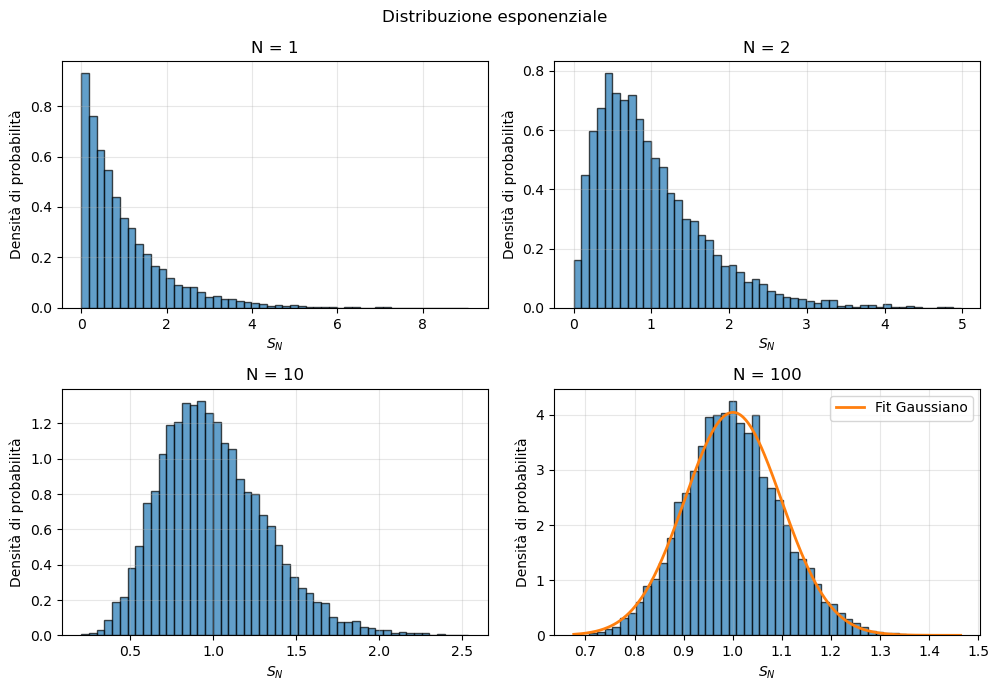

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes = axes.flatten()

for i, n in enumerate(valori_n):

    dati = exponential[:, i]

    axes[i].hist(
        dati,
        bins=50,
        density=True,
        alpha=0.7,
        edgecolor="black"
    )

    axes[i].set_title(f"N = {n}")
    axes[i].set_xlabel(r"$S_N$")
    axes[i].set_ylabel("Densità di probabilità")
    axes[i].grid(alpha=0.3)


# Fit Gaussiano per N = 100
dati_n100 = exponential[:, 3]

mu_fit_exponential, sigma_fit_exponential = norm.fit(dati_n100)

x = np.linspace(dati_n100.min(), dati_n100.max(), 500)

axes[3].plot(
    x,
    norm.pdf(x, mu_fit_exponential, sigma_fit_exponential),
    linewidth=2,
    label="Fit Gaussiano"
)

axes[3].legend()

plt.suptitle("Distribuzione esponenziale")
plt.tight_layout()

plt.show()

Per $N=1$ la distribuzione mantiene la forte asimmetria caratteristica della distribuzione esponenziale.

Già per $N=2$ e $N=10$ la distribuzione della media cambia progressivamente forma.

Per $N=100$ risulta invece quasi simmetrica e ben descritta da una distribuzione Gaussiana centrata attorno a

$$
\langle S_N\rangle=1.
$$

Anche in questo caso si osserva quindi il comportamento previsto dal Teorema del Limite Centrale.

La dispersione diminuisce all'aumentare di $N$ secondo

$$
\sigma_{S_N}=\frac{1}{\sqrt{N}}.
$$

## Distribuzione di Cauchy-Lorentz

Si consideri infine la distribuzione di Cauchy-Lorentz

$$
p(x)
=
\frac{1}{\pi}
\frac{\Gamma}
{(x-\mu)^2+\Gamma^2},
$$

con

$$
\mu=0,
\qquad
\Gamma=1.
$$

A differenza delle distribuzioni uniforme ed esponenziale, la distribuzione di Cauchy presenta code molto lunghe e **non possiede né media né varianza finite**.

Non sono quindi soddisfatte le ipotesi del Teorema del Limite Centrale standard.

La distribuzione di Cauchy appartiene inoltre alla famiglia delle distribuzioni stabili: la media di più variabili di Cauchy indipendenti continua ad avere una distribuzione di Cauchy.

Nel nostro caso, se

$$
x_i\sim C(0,1),
$$

allora anche

$$
S_N=\frac{1}{N}\sum_{i=1}^{N}x_i
$$

segue una distribuzione di Cauchy con gli stessi parametri.

Di conseguenza, aumentando $N$ non ci si aspetta una convergenza verso una Gaussiana e nemmeno una progressiva riduzione della larghezza della distribuzione.

Per $N=100$ i risultati vengono confrontati con un fit di Cauchy-Lorentz.

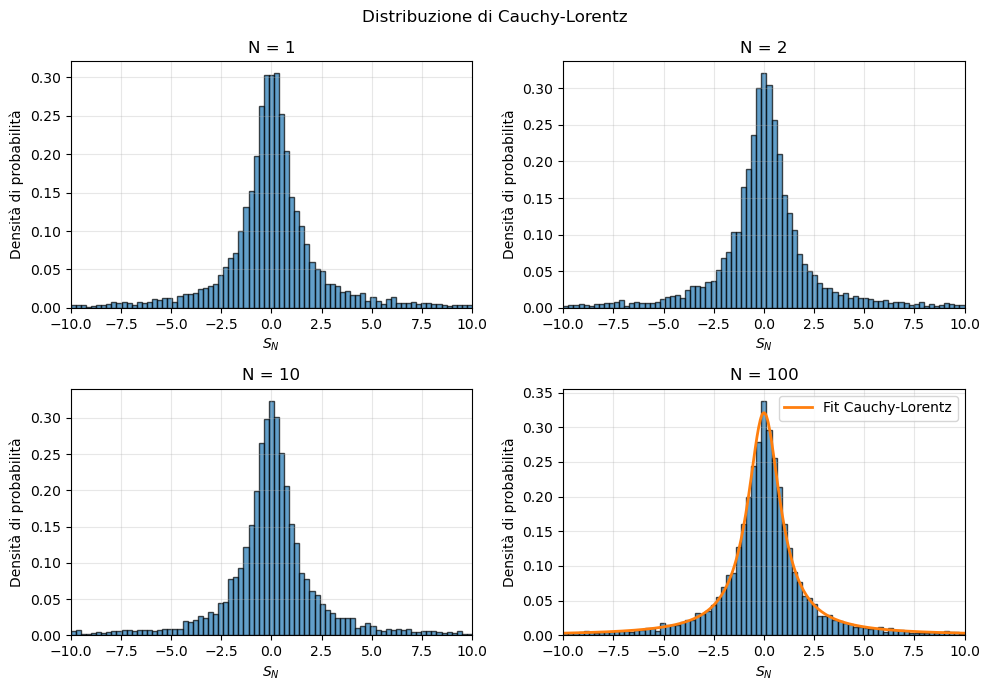

In [48]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes = axes.flatten()

# Intervallo mostrato nei grafici
limite = 10

for i, n in enumerate(valori_n):

    dati = lorentzian[:, i]

    # Bin comuni nell'intervallo [-10, 10]
    bins = np.linspace(-limite, limite, 80)

    # Pesi scelti in modo da mantenere la corretta normalizzazione
    # rispetto al numero totale di realizzazioni
    larghezza_bin = bins[1] - bins[0]

    pesi = np.ones_like(dati) / (len(dati) * larghezza_bin)

    axes[i].hist(
        dati,
        bins=bins,
        weights=pesi,
        alpha=0.7,
        edgecolor="black"
    )

    axes[i].set_xlim(-limite, limite)

    axes[i].set_title(f"N = {n}")
    axes[i].set_xlabel(r"$S_N$")
    axes[i].set_ylabel("Densità di probabilità")
    axes[i].grid(alpha=0.3)


# Fit Cauchy per N = 100
dati_n100 = lorentzian[:, 3]

mu_fit_lorentz, gamma_fit_lorentz = cauchy.fit(dati_n100)

x = np.linspace(-limite, limite, 500)

axes[3].plot(
    x,
    cauchy.pdf(x, loc=mu_fit_lorentz, scale=gamma_fit_lorentz),
    linewidth=2,
    label="Fit Cauchy-Lorentz"
)

axes[3].legend()

plt.suptitle("Distribuzione di Cauchy-Lorentz")
plt.tight_layout()

plt.show()

La distribuzione di $S_N$ rimane molto simile alla distribuzione di partenza anche aumentando $N$.

In particolare, a differenza dei casi uniforme ed esponenziale:

- la distribuzione non tende a una Gaussiana;
- le code rimangono molto lunghe;
- la larghezza della distribuzione non diminuisce come $1/\sqrt{N}$.

Questo comportamento è una conseguenza del fatto che la distribuzione di Cauchy non possiede varianza finita e non soddisfa quindi le ipotesi del Teorema del Limite Centrale standard. La distribuzione di Cauchy è tuttavia stabile, e quindi ha come attrattore se stessa.

Il fit per $N=100$ mostra che i dati continuano a essere compatibili con una distribuzione di Cauchy-Lorentz.

# 01.3 — Esperimento dell'ago di Buffon

In questa parte utilizziamo una simulazione Monte Carlo dell'**esperimento dell'ago di Buffon** per ottenere una stima numerica di $\pi$.

Si considerino un insieme di linee parallele equidistanti, separate da una distanza $d$, e si lanci casualmente un ago di lunghezza $L$, con

$$
L<d.
$$

La probabilità che l'ago intersechi una delle linee è

$$
P_{\mathrm{hit}}
=
\frac{2L}{\pi d}.
$$

Se si effettuano $N_{\mathrm{thr}}$ lanci e si misurano $N_{\mathrm{hit}}$ intersezioni, è possibile stimare la probabilità tramite

$$
P_{\mathrm{hit}}
\simeq
\frac{N_{\mathrm{hit}}}{N_{\mathrm{thr}}}.
$$

Sostituendo nella relazione teorica si ottiene quindi una stima di $\pi$:

$$
\pi
\simeq
\frac{2L N_{\mathrm{thr}}}
{d N_{\mathrm{hit}}}.
$$

Nella simulazione è stato scelto

$$
d=2L,
$$

per cui la relazione si semplifica in

$$
\pi
\simeq
\frac{N_{\mathrm{thr}}}{N_{\mathrm{hit}}}.
$$

L'obiettivo è quindi utilizzare il numero di intersezioni osservate nella simulazione per ricavare una stima progressiva di $\pi$ e della relativa incertezza statistica.

## Geometria della simulazione

Grazie all'invarianza per traslazioni lungo la direzione parallela alle linee, non è necessario simulare esplicitamente un piano contenente molte linee.

È sufficiente considerare una singola regione compresa tra due linee consecutive:

$$
y=0,
\qquad
y=d.
$$

Il centro dell'ago viene estratto uniformemente nell'intervallo

$$
y_c\in[0,d).
$$

La distanza del centro dalla linea più vicina è quindi

$$
h
=
\min(y_c,d-y_c).
$$

L'orientazione dell'ago viene generata senza utilizzare il valore di $\pi$.

Si estrae un punto casuale $(x,y)$ all'interno del disco unitario e si normalizza il vettore:

$$
\vec{u}
=
\frac{(x,y)}
{\sqrt{x^2+y^2}}.
$$

Poiché il disco è rotazionalmente simmetrico, il versore ottenuto ha una direzione uniformemente distribuita nel piano.

Indicando con $u_y$ la componente verticale del versore, la massima distanza verticale tra il centro dell'ago e una delle sue estremità è

$$
\Delta y
=
\frac{L}{2}|u_y|.
$$

L'ago interseca quindi una linea quando

$$
\Delta y\geq h.
$$

In questo modo l'intera simulazione viene effettuata senza utilizzare $\pi$ per generare l'orientazione dell'ago.

## Data blocking

Sono stati effettuati complessivamente

$$
M=10^8
$$

lanci, suddivisi in blocchi da

$$
L_{\mathrm{blocco}}=10^5
$$

lanci ciascuno.

Il numero totale di blocchi è quindi

$$
N
=
\frac{10^8}{10^5}
=
10^3.
$$

Per ogni blocco viene calcolata una stima indipendente di $\pi$.

A partire da queste stime si costruisce poi:

- la stima progressiva di $\pi$;
- l'incertezza statistica progressiva ottenuta tramite data blocking.

Il file `Pi_Buffon.txt` contiene:

1. stima di $\pi$ nel singolo blocco;
2. stima progressiva di $\pi$;
3. errore statistico progressivo.

In [68]:
import numpy as np
import matplotlib.pyplot as plt

# Lettura dei risultati della simulazione
pi_blocco, pi_progressivo, errore_pi = np.loadtxt(
    "Esercizio_01.3\Pi_Buffon.txt",
    unpack=True
)

# Parametri della simulazione
numero_lanci = 100_000_000
lanci_per_blocco = 10_0000
numero_blocchi = len(pi_blocco)

# Numero cumulativo di lanci utilizzati dopo ogni blocco
lanci_cumulativi = np.arange(1, numero_blocchi + 1) * lanci_per_blocco

print(f"Numero totale di lanci: {numero_lanci}")
print(f"Lanci per blocco: {lanci_per_blocco}")
print(f"Numero di blocchi: {numero_blocchi}")

Numero totale di lanci: 100000000
Lanci per blocco: 100000
Numero di blocchi: 1000


## Stima progressiva di $\pi$

Ogni blocco di $10^5$ lanci fornisce una stima indipendente di $\pi$:

$$
\pi_i
=
\frac{2L\,N_{\mathrm{thr}}}
{d\,N_{\mathrm{hit}}},
$$

dove $N_{\mathrm{thr}}=10^5$ è il numero di lanci effettuati nel singolo blocco.

A partire dalle stime ottenute nei diversi blocchi viene costruita la media progressiva

$$
\langle\pi\rangle_N
=
\frac{1}{N}
\sum_{i=1}^{N}\pi_i,
$$

dove $N$ indica il numero di blocchi utilizzati.

Si rappresentano quindi $\langle\pi\rangle_N$ in funzione di $N$, insieme alla sua incertezza statistica progressiva.

Il valore teorico di $\pi$ viene rappresentato come una linea orizzontale, in modo da osservare direttamente la convergenza della simulazione.


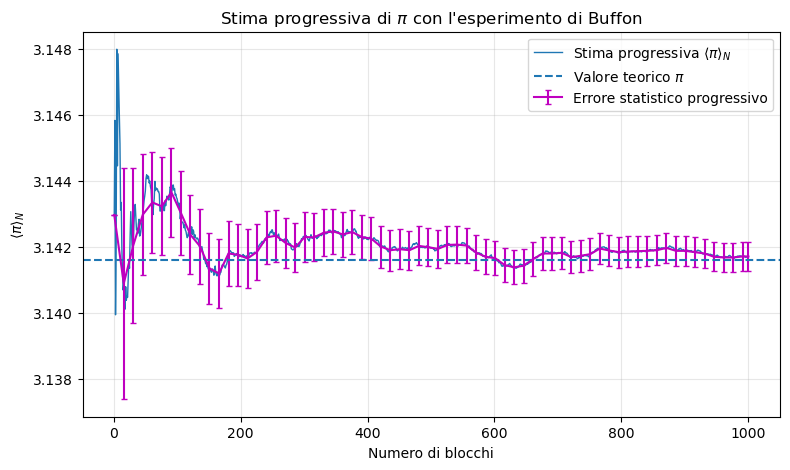

In [86]:
# Valore teorico di pi
# Viene utilizzato solamente per confrontare il risultato della simulazione
pi_teorico = np.pi

# Numero di blocchi utilizzati nella media progressiva
blocchi = np.arange(1, numero_blocchi + 1)

plt.figure(figsize=(9, 5))

# Andamento completo della stima progressiva
plt.plot(
    blocchi,
    pi_progressivo,
    linewidth=1,
    label=r"Stima progressiva $\langle\pi\rangle_N$"
)

# Mostriamo le barre d'errore solo ogni 15 blocchi
passo_plot = 15
indici = np.arange(0, numero_blocchi, passo_plot)

# Aggiungo anche l'ultimo blocco se non è già presente
if indici[-1] != numero_blocchi - 1:
    indici = np.append(indici, numero_blocchi - 1)

plt.errorbar(
    blocchi[indici],
    pi_progressivo[indici],
    yerr=errore_pi[indici],
    fmt="m",
    markersize=3,
    capsize=2,
    label="Errore statistico progressivo"
)

# Valore teorico di pi
plt.axhline(
    pi_teorico,
    linestyle="--",
    linewidth=1.5,
    label=rf"Valore teorico $\pi$"
)

plt.xlabel("Numero di blocchi")
plt.ylabel(r"$\langle\pi\rangle_N$")
plt.title(r"Stima progressiva di $\pi$ con l'esperimento di Buffon")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

La stima progressiva presenta inizialmente oscillazioni più ampie, perché viene calcolata utilizzando un numero ancora piccolo di blocchi.

All'aumentare di $N$, ogni nuovo blocco contribuisce alla media progressiva e la stima tende a stabilizzarsi attorno al valore teorico $\pi$

Contemporaneamente diminuisce anche l'incertezza statistica sulla media.



In [79]:
# Risultato ottenuto utilizzando tutti i blocchi
pi_finale = pi_progressivo[-1]
errore_finale = errore_pi[-1]

# Differenza rispetto al valore teorico
scarto_finale = pi_finale - pi_teorico

print("Risultato finale:")
print()
print(f"Numero di blocchi utilizzati = {numero_blocchi}")
print(f"Numero totale di lanci       = {numero_lanci}")
print()
print(f"pi simulato = {pi_finale:.8f} ± {errore_finale:.8f}")
print(f"pi teorico  = {pi_teorico:.8f}")
print(f"Scarto      = {scarto_finale:+.8f}")

Risultato finale:

Numero di blocchi utilizzati = 1000
Numero totale di lanci       = 100000000

pi simulato = 3.14171000 ± 0.00043439
pi teorico  = 3.14159265
Scarto      = +0.00011735


## Compatibilità con il valore teorico

La sola vicinanza tra la stima ottenuta e il valore teorico non è sufficiente per valutare quantitativamente il risultato: bisogna tenere conto anche dell'incertezza statistica.

Possiamo quindi confrontare lo scarto

$$
\Delta\pi
=
\langle\pi\rangle_N-\pi
$$

con l'errore statistico finale $\sigma_\pi$.

Definiamo lo $z$-score:

$$
z
=
\frac{
\langle\pi\rangle_N-\pi
}{
\sigma_\pi
}.
$$

Il valore di $|z|$ indica di quante deviazioni standard la stima simulata si trova dal valore teorico.



In [80]:
# Numero di deviazioni standard che separano il risultato dal valore teorico
z_score = scarto_finale / errore_finale

print(f"Stima finale di pi:          {pi_finale:.8f}")
print(f"Valore teorico:              {pi_teorico:.8f}")
print(f"Scarto dal valore teorico:  {scarto_finale:+.8f}")
print(f"Errore statistico finale:   {errore_finale:.8f}")
print(f"z-score:                     {z_score:.2f}")

Stima finale di pi:          3.14171000
Valore teorico:              3.14159265
Scarto dal valore teorico:  +0.00011735
Errore statistico finale:   0.00043439
z-score:                     0.27


Il valore simulato è distante 0.27 $\sigma$ dal valore toerico, di conseguenza l'esperimento può considerarsi riuscito

## Andamento dell'incertezza statistica

Il data blocking permette anche di osservare come varia l'incertezza sulla stima progressiva al crescere del numero di blocchi.

Se le stime ottenute nei diversi blocchi possono essere considerate indipendenti, ci aspettiamo che l'errore sulla media diminuisca approssimativamente come

$$
\sigma_{\langle\pi\rangle}
\propto
\frac{1}{\sqrt{N}},
$$

dove $N$ è il numero di blocchi utilizzati.

Rappresentiamo quindi l'errore progressivo in funzione del numero di blocchi.

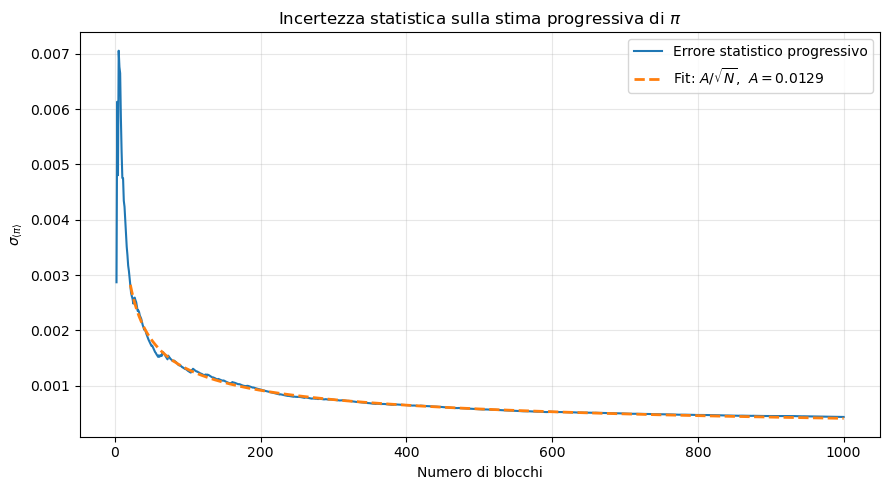

A = 0.012942 ± 0.000013


In [87]:
from scipy.optimize import curve_fit

# Funzione attesa per l'errore sulla media
def errore_teorico(n, A):
    return A / np.sqrt(n)


# Escludiamo i primi blocchi, dove la stima dell'errore e' molto instabile
inizio_fit = 20

blocchi_fit = blocchi[inizio_fit:]
errori_fit = errore_pi[inizio_fit:]


# Fit della funzione A / sqrt(N)
parametri, covarianza = curve_fit(
    errore_teorico,
    blocchi_fit,
    errori_fit
)

A_fit = parametri[0]
errore_A = np.sqrt(covarianza[0, 0])


# Curva ottenuta dal fit
errore_fit = errore_teorico(blocchi_fit, A_fit)


# Grafico
plt.figure(figsize=(9, 5))

# Errore statistico ottenuto dalla simulazione
plt.plot(
    blocchi[1:],
    errore_pi[1:],
    linewidth=1.5,
    label="Errore statistico progressivo"
)

# Fit A / sqrt(N)
plt.plot(
    blocchi_fit,
    errore_fit,
    linestyle="--",
    linewidth=2,
    label=rf"Fit: $A/\sqrt{{N}}$,  $A={A_fit:.4f}$"
)

plt.xlabel("Numero di blocchi")
plt.ylabel(r"$\sigma_{\langle\pi\rangle}$")
plt.title(r"Incertezza statistica sulla stima progressiva di $\pi$")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


print(f"A = {A_fit:.6f} ± {errore_A:.6f}")

L'andamento dell'incertezza statistica è compatibile con la legge attesa

$$
\sigma_{\langle\pi\rangle}(N)
\propto
\frac{1}{\sqrt{N}}.
$$

Il fit è stato effettuato utilizzando la funzione

$$
f(N)=\frac{A}{\sqrt{N}},
$$

dove $A$ è un parametro libero.

I primissimi blocchi sono stati esclusi dal fit perché, quando il numero di blocchi è ancora piccolo, la stima della deviazione statistica è fortemente soggetta a fluttuazioni.

L'accordo tra i dati e l'andamento $1/\sqrt{N}$ conferma il comportamento atteso per l'errore sulla media di $N$ stime statisticamente indipendenti.

## Stime di $\pi$ nei singoli blocchi

È utile distinguere la **stima del singolo blocco** dalla **stima progressiva**.

Ogni blocco contiene $10^5$ lanci e fornisce una propria stima $\pi_i$. Queste stime presentano fluttuazioni statistiche relativamente ampie.

La media progressiva

$$
\langle\pi\rangle_N
=
\frac{1}{N}\sum_{i=1}^{N}\pi_i
$$

combina invece un numero crescente di blocchi e risulta quindi molto più stabile.

Possiamo confrontare direttamente le stime dei singoli blocchi con il valore teorico di $\pi$.

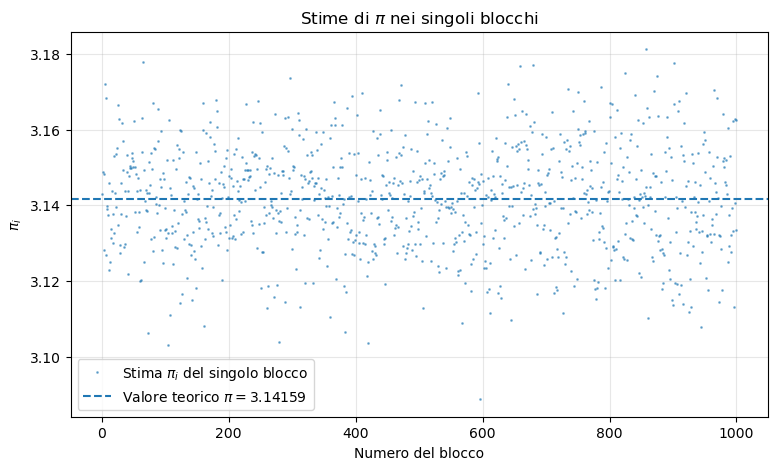

In [82]:
plt.figure(figsize=(9, 5))

plt.plot(
    blocchi,
    pi_blocco,
    ".",
    markersize=2,
    alpha=0.5,
    label=r"Stima $\pi_i$ del singolo blocco"
)

plt.axhline(
    pi_teorico,
    linestyle="--",
    linewidth=1.5,
    label=rf"Valore teorico $\pi = {pi_teorico:.5f}$"
)

plt.xlabel("Numero del blocco")
plt.ylabel(r"$\pi_i$")
plt.title(r"Stime di $\pi$ nei singoli blocchi")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

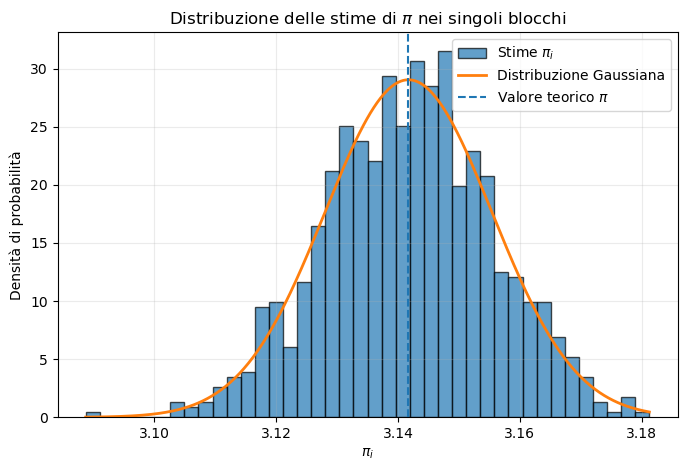

In [84]:
from scipy.stats import norm

# Media e deviazione standard delle stime dei singoli blocchi
media_pi_blocchi = np.mean(pi_blocco)
sigma_pi_blocchi = np.std(pi_blocco, ddof=1)

# Intervallo per la curva gaussiana
x = np.linspace(
    pi_blocco.min(),
    pi_blocco.max(),
    500
)

# Distribuzione gaussiana con media e sigma ottenute dai dati
gaussiana = norm.pdf(
    x,
    loc=media_pi_blocchi,
    scale=sigma_pi_blocchi
)

plt.figure(figsize=(8, 5))

plt.hist(
    pi_blocco,
    bins=40,
    density=True,
    alpha=0.7,
    edgecolor="black",
    label=r"Stime $\pi_i$"
)

plt.plot(
    x,
    gaussiana,
    linewidth=2,
    label="Distribuzione Gaussiana"
)

plt.axvline(
    np.pi,
    linestyle="--",
    linewidth=1.5,
    label=rf"Valore teorico $\pi$"
)

plt.xlabel(r"$\pi_i$")
plt.ylabel("Densità di probabilità")
plt.title(r"Distribuzione delle stime di $\pi$ nei singoli blocchi")

plt.legend()
plt.grid(alpha=0.25)

plt.show()

Ogni valore $\pi_i$ è ottenuto utilizzando $10^5$ lanci indipendenti.

Il numero di intersezioni osservato in ciascun blocco è quindi la somma di un grande numero di variabili casuali di Bernoulli. Per il Teorema del Limite Centrale, la distribuzione della frequenza di intersezione tende a una distribuzione Gaussiana.

Di conseguenza, anche le stime $\pi_i$ ottenute nei singoli blocchi risultano approssimativamente distribuite attorno al valore teorico secondo una forma Gaussiana.

L'accordo tra l'istogramma delle stime di blocco e la curva Gaussiana è in accordo quindi col teorema del limite centrale.

## Conclusioni

L'esperimento dell'ago di Buffon permette di ottenere una stima numerica di $\pi$ a partire da un problema geometrico e probabilistico.

Nella simulazione sono stati effettuati

$$
10^8
$$

lanci, suddivisi in

$$
10^3
$$

blocchi contenenti $10^5$ lanci ciascuno.

L'orientazione casuale dell'ago è stata generata senza utilizzare il valore di $\pi$, sfruttando la simmetria rotazionale del disco unitario.

Per ogni blocco è stata ottenuta una stima indipendente $\pi_i$ e, mediante il metodo del data blocking, sono state calcolate la media progressiva

$$
\langle\pi\rangle_N
$$

e la relativa incertezza statistica.

Dal grafico si osserva che, aumentando il numero di blocchi, la stima progressiva tende a stabilizzarsi attorno al valore teorico di $\pi$, mentre l'incertezza statistica diminuisce.

